# CNN: gatos contra perros

Clasificación binaria del dataset `cats_vs_dogs` de TensorFlow Datasets con cuatro modelos de complejidad creciente: dos capas convolucionales, max pooling, regularización (aumento de datos y dropout) y transfer learning con MobileNetV2. Pensado para Colab con GPU.

# 1. Importaciones:

In [1]:
%pip install -q importlib_resources  # tensorflow_datasets lo necesita en Python 3.13
import numpy as np
import tensorflow_datasets as tfds
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers

# 2. Obtención de datos:

In [2]:
dataset, info = tfds.load('cats_vs_dogs', with_info=True, as_supervised=True)
dataset = dataset['train']
class_names = ['cat', 'dog']

size = tf.data.experimental.cardinality(dataset).numpy()
print(f'number of images:{size}')

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.LNIIQ8_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
number of images:23262


# 3. Procesamiento de datos:

Estandarizar el tamaño de las imagenes:


In [3]:
image_size = (96, 96, 3)


def preprocess_img(images, size=(96, 96)):
    return tf.image.resize(images, size)

dataset = dataset.map(lambda images, labels: (preprocess_img(images), labels))

Dividir el conjunto de datos:

In [4]:
'''
Se divide el conjunto de datos en tres partes: entrenamiento, validación y prueba
'''

#batch_size se define como 32, lo que significa que cada lote de datos tendrá 32 elementos
batch_size = 32

#fracción del tamaño total size, representa el 75% del tamaño total
train_size = int(0.75 * size)

#fracción del tamaño total size, representa el 10% del tamaño total
val_size = int(0.1 * size)

#toma los primeros train_size elementos del conjunto de datos dataset (el 75%)
train_ds = dataset.take(train_size)

# Se guarda en caché antes de barajar, para que cada época se rebaraje (buffer de 1000) y luego se agrupa en lotes de 32
train_ds = train_ds.cache().shuffle(1000).batch(batch_size)

#contiene los datos que no fueron tomados por train_ds, el 25% restante del conjunto de datos
remaining = dataset.skip(train_size)

#toma val_size elementos de remaining (el 10% del conjunto de datos original)
val_ds = remaining.take(val_size)

#contiene los datos restantes después de dividir val_ds, el 15% del conjunto de datos original
test_ds = remaining.skip(val_size)

#se reorganizan aleatoriamente, se agrupan en lotes y se almacena en caché
val_ds = val_ds.shuffle(1000).batch(batch_size).cache()
test_ds = test_ds.batch(batch_size).cache()

In [5]:
'''
prefetch permite que el preprocesamiento y el modelo de entrenamiento se superpongan.
AUTOTUNE hace que TensorFlow elija automáticamente el mejor tamaño de buffer para prefetching,
así se mejora la eficiencia al cargar datos.
'''
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

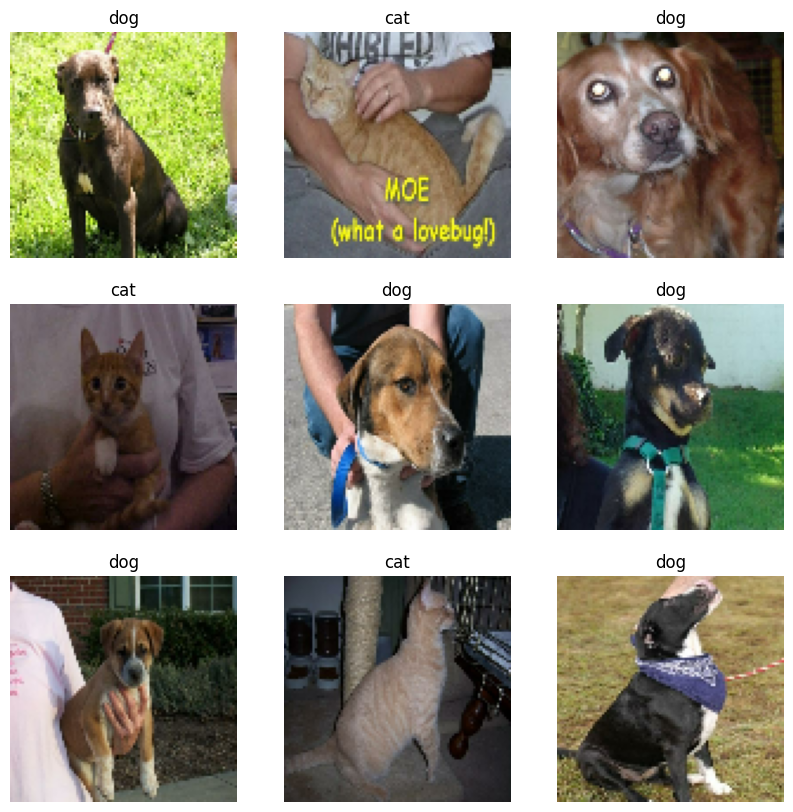

In [6]:
'''
Visualizar una partecita de las imágenes provenientes del dataset de entrenamiento
'''
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

# 4. Modelo 1: dos capas convolucionales

Sin pooling ni regularización: es la línea base.

In [7]:
# Define la entrada con el tamaño de imagen, acepta imágenes de 96x96 píxeles y 3 canales (RGB)
inputs = tf.keras.Input(shape=(96, 96, 3), name='input')

# Normaliza las imágenes al rango [0, 1] para estabilizar y acelerar el proceso de entrenamiento.
rescaling = tf.keras.layers.Rescaling(1./255)(inputs)

# Capa 1 Convolucional
conv_1 = tf.keras.layers.Conv2D(
    filters=32,          # Número de filtros (capta patrones básicos (bordes, texturas) al inicio de la red)
    kernel_size=(3, 3),  # Tamaño del kernel
    activation='relu',   # Activación ReLU (brinda no linealidad al modelo y ayuda a aprender representaciones más complejas al mitigar el problema del gradiente desaparecido)
    name='conv_1'
)(rescaling)

# Capa 2 Convolucional
conv_2 = tf.keras.layers.Conv2D(
    filters=64,          # Número de filtros (capta características más complejas y específicas de las imágenes)
    kernel_size=(3, 3),  # Tamaño del kernel
    activation='relu',   # Activación ReLU
    name='conv_2'
)(conv_1)


# Fully-connected

# Aplanamiento para conectar las capas convolucionales con la capa densa de salida
flat = tf.keras.layers.Flatten(name='flatten')(conv_2)

# Capa densa de salida
outputs = tf.keras.layers.Dense(
    units=1,              # Para dar un solo valor (si es más cercano a 0(clase 0) o a 1(clase 1))
    activation='sigmoid', # Activación sigmoid para obtener una probabilidad
    name='output'
)(flat)

# Se define el modelo
modelo_1 = tf.keras.Model(inputs=inputs, outputs=outputs)

# Imprime la estructura del modelo
modelo_1.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 92, 92, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 541696)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │       541,697 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 561,089 (2.14 MB)

 Trainable params: 561,089 (2.14 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
modelo_1.compile(
    optimizer='adam', #Ajusta los pesos de la red neuronal de manera eficiente dando una tasa de aprendizaje adaptativa a cada parámetro (converge rápidamente)
    loss=tf.keras.losses.BinaryCrossentropy(), # Calcula la diferencia entre la distribución de probabilidad predicha y la real para clasificacion binaria
    metrics=['accuracy'] #Da la proporción de predicciones correctas durante el entrenamiento y evalúa del modelo
)

In [9]:
# Máximo 8 épocas; EarlyStopping corta antes si la pérdida de validación deja de mejorar
epochs = 8

#Se crea una instancia de la clase `EarlyStopping`, detiene el entrenamiento del modelo de manera anticipada si no hay mejora en la métrica
es_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=2, # Número de épocas sin mejora antes de detenerse
    restore_best_weights=True,  # Se queda con los pesos de la mejor época
    verbose=1)  # Muestra mensajes durante el entrenamiento

historia = modelo_1.fit(
    train_ds,                  # Conjunto de datos de entrenamiento
    validation_data=val_ds,    # Conjunto de datos de validación
    epochs=epochs,
    callbacks=[es_callback],
)

Epoch 1/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 53s 77ms/step - accuracy: 0.6408 - loss: 0.6729 - val_accuracy: 0.7081 - val_loss: 0.5670
Epoch 2/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.7599 - loss: 0.4961 - val_accuracy: 0.7120 - val_loss: 0.5640
Epoch 3/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.8366 - loss: 0.3705 - val_accuracy: 0.7369 - val_loss: 0.6059
Epoch 4/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.9085 - loss: 0.2324 - val_accuracy: 0.7330 - val_loss: 0.7665
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.


In [10]:
resultados = modelo_1.evaluate(test_ds, verbose=1) #Acá se evalúa con el tercer conjunto de datos: test
print('Test Loss: {}'.format(resultados[0]))
print('Test Accuracy: {}'.format(resultados[1]))

110/110 ━━━━━━━━━━━━━━━━━━━━ 21s 38ms/step - accuracy: 0.7103 - loss: 0.5761
Test Loss: 0.5761369466781616
Test Accuracy: 0.7103151679039001


**Análisis:** exactitud de 0,71 en prueba. Sin pooling, la capa densa recibe mapas de características muy grandes y el modelo memoriza rápido: en la época 4 llega a 0,91 en entrenamiento contra 0,73 en validación, y EarlyStopping se queda con los pesos de la época 2. Es mejor que el azar, pero insuficiente.

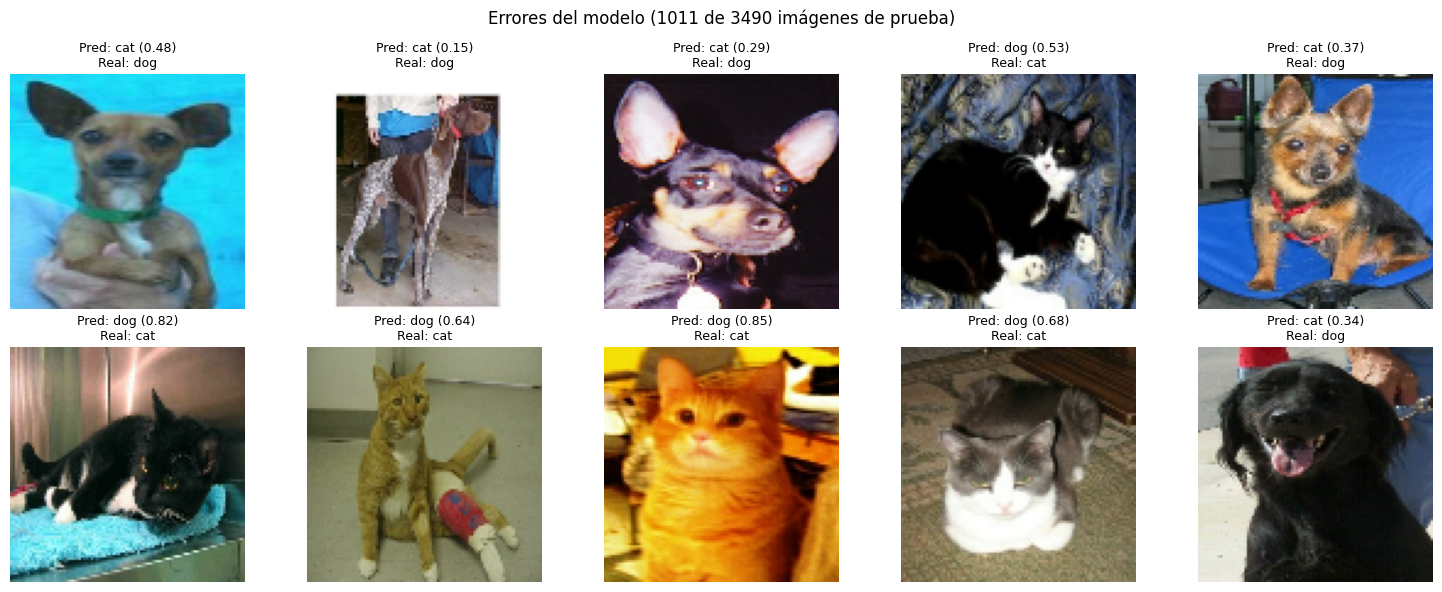

In [11]:
# Muestra en una cuadrícula algunos ejemplos que el modelo clasifica mal
def mostrar_errores(x_test, model, y_test, n_samples=10):
    labels = y_test.astype(np.int32)
    predictions = model.predict(x_test, verbose=0).squeeze()

    # Clases (0 o 1) con umbral de 0.5 sobre la salida sigmoide
    preds = (predictions > 0.5).astype(np.int32)

    bad_pred_inds = np.where(preds != labels)[0]
    n_samples = min(len(bad_pred_inds), n_samples)
    samples_inds = np.random.default_rng(42).choice(bad_pred_inds, n_samples, replace=False)

    plt.figure(figsize=(15, 6))
    for k, ind in enumerate(samples_inds):
        plt.subplot(2, (n_samples + 1) // 2, k + 1)
        plt.imshow(x_test[ind].astype("uint8"))
        plt.title('Pred: {0} ({1:.2f})\nReal: {2}'.format(
            class_names[preds[ind]], predictions[ind], class_names[labels[ind]]), fontsize=9)
        plt.axis('off')
    plt.suptitle(f'Errores del modelo ({len(bad_pred_inds)} de {len(labels)} imágenes de prueba)')
    plt.tight_layout()
    plt.show()

# Convertir test_ds a arrays de numpy
x_test = []
y_test = []
for images, labels in test_ds:
    x_test.append(images.numpy())
    y_test.append(labels.numpy())

x_test = np.concatenate(x_test, axis=0)
y_test = np.concatenate(y_test, axis=0)

# Llamar a la función con los datos reales
mostrar_errores(x_test, modelo_1, y_test, n_samples=10)

# 5. Modelo 2: con max pooling

La misma arquitectura con una capa de max pooling después de cada convolución, todavía sin regularización.

In [12]:
inputs = tf.keras.Input(shape=(96, 96, 3), name='input')  # Entrada con tamaño 96x96x3
reescaling = tf.keras.layers.Rescaling(1./255)(inputs)  # Normalización

# Capa 1: Convolucional + MaxPooling
conv_1 = tf.keras.layers.Conv2D(
    filters=32,
    kernel_size=(3, 3),
    activation='relu',
    name='conv_1'
)(reescaling)
pool_1 = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool_1')(conv_1) # Con pooling reduce la cantidad de parámetros (disminuye el costo computacional) y ayuda a la red a enfocarse en las características más prominentes

# Capa 2: Convolucional + MaxPooling
conv_2 = tf.keras.layers.Conv2D(
    filters=64,
    kernel_size=(3, 3),
    activation='relu',
    name='conv_2'
)(pool_1)
pool_2 = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool_2')(conv_2)

# Aplanamiento
flat = tf.keras.layers.Flatten(name='flatten')(pool_2)

# Capa densa de salida (clasificación binaria)
outputs = tf.keras.layers.Dense(
    units=1,              # 1 unidad para salida binaria
    activation='sigmoid', # Activación sigmoid para clasificación binaria
    name='output'
)(flat)

# Crear el modelo
modelo_2 = tf.keras.Model(inputs=inputs, outputs=outputs)

modelo_2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │        30,977 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,369 (196.75 KB)

 Trainable params: 50,369 (196.75 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
modelo_2.compile(
    optimizer='adam',
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

epochs = 8

es_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True,
    verbose=1)

historia = modelo_2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[es_callback],
)

Epoch 1/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.6681 - loss: 0.5984 - val_accuracy: 0.7412 - val_loss: 0.5214
Epoch 2/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.7680 - loss: 0.4938 - val_accuracy: 0.7365 - val_loss: 0.5245
Epoch 3/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.7931 - loss: 0.4408 - val_accuracy: 0.7790 - val_loss: 0.4682
Epoch 4/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8231 - loss: 0.3937 - val_accuracy: 0.7984 - val_loss: 0.4499
Epoch 5/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8423 - loss: 0.3571 - val_accuracy: 0.8035 - val_loss: 0.4649
Epoch 6/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8662 - loss: 0.3148 - val_accuracy: 0.8083 - val_loss: 0.4718
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 4.


In [14]:
resultados = modelo_2.evaluate(test_ds, verbose=1)
print('Test Loss: {}'.format(resultados [0]))
print('Test Accuracy: {}'.format(resultados [1]))

110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8037 - loss: 0.4519
Test Loss: 0.45186010003089905
Test Accuracy: 0.8037249445915222


**Análisis:** exactitud de 0,80 en prueba, 9 puntos más que el modelo 1. El max pooling reduce el tamaño de los mapas y los parámetros de la capa densa, y vuelve la red menos sensible a pequeños desplazamientos del objeto. El sobreajuste aparece más tarde: la mejor época es la 4.

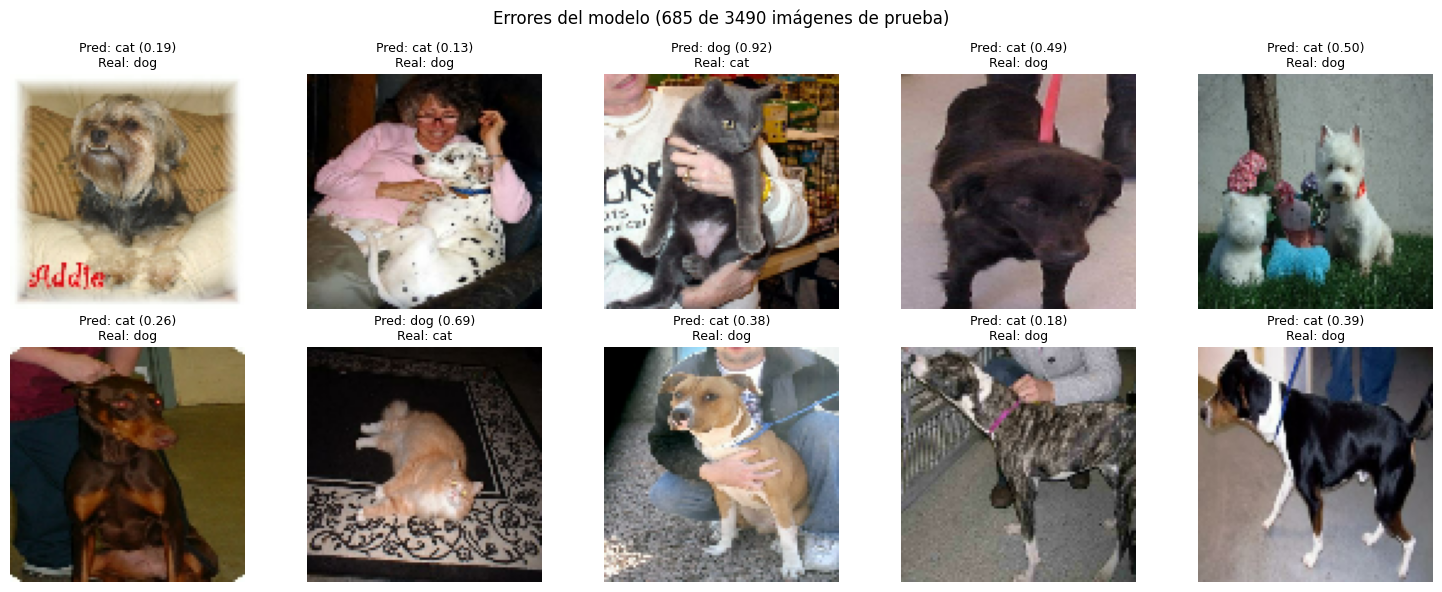

In [15]:
mostrar_errores(x_test, modelo_2, y_test, n_samples=10)

# 6. Modelo 3: más capas y regularización

Cuatro bloques convolución + pooling, aumento de datos (volteo horizontal y rotación) y dropout. El objetivo es superar 0,8 de exactitud en prueba.

In [16]:
data_augmentation = tf.keras.Sequential(
  [
    layers.RandomFlip("horizontal"),  # Volteo horizontal
    layers.RandomRotation(0.25),      # Rotación aleatoria
  ]
)

In [17]:
# Entrada
inputs = tf.keras.Input(shape=(96, 96, 3), name='input')
reescaling = tf.keras.layers.Rescaling(1./255)(inputs)  # Normalización

# Ampliación de datos (aplicada a las imágenes de entrada)
augmented = data_augmentation(reescaling)

# Capa 1: Convolucional + MaxPooling
conv_1 = tf.keras.layers.Conv2D(
    filters=32,
    kernel_size=(3, 3),
    activation='relu',
    name='conv_1'
)(augmented)
pool_1 = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool_1')(conv_1)

# Capa 2: Convolucional + MaxPooling
conv_2 = tf.keras.layers.Conv2D(
    filters=64,
    kernel_size=(3, 3),
    activation='relu',
    name='conv_2'
)(pool_1)
pool_2 = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool_2')(conv_2)

# Capa 3: Convolucional + MaxPooling
conv_3 = tf.keras.layers.Conv2D(
    filters=128,
    kernel_size=(3, 3),
    activation='relu',
    name='conv_3'
)(pool_2)
pool_3 = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool_3')(conv_3)

# Capa 4: Convolucional + MaxPooling
conv_4 = tf.keras.layers.Conv2D(
    filters=256,
    kernel_size=(3, 3),
    activation='relu',
    name='conv_4'
)(pool_3)
pool_4 = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool_4')(conv_4)

# Aplanamiento
flat = tf.keras.layers.Flatten(name='flatten')(pool_4)

# Capa densa
dense_1 = tf.keras.layers.Dense(512, activation='relu', name='dense_1')(flat)
dropout = tf.keras.layers.Dropout(0.5)(dense_1)  # Regularización con Dropout

# Capa de salida (clasificación binaria)
outputs = tf.keras.layers.Dense(
    units=1,              # 1 unidad para salida binaria
    activation='sigmoid', # Activación sigmoid para clasificación binaria
    name='output'
)(dropout)

# Crear el modelo
modelo_3 = tf.keras.Model(inputs=inputs, outputs=outputs)

modelo_3.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_4 (Conv2D)                 │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_4 (MaxPooling2D)           │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,486,593 (9.49 MB)

 Trainable params: 2,486,593 (9.49 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
modelo_3.compile(
    optimizer='adam',
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

epochs = 8

es_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True,
    verbose=1)

historia = modelo_3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[es_callback],
)

Epoch 1/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.5595 - loss: 0.6806 - val_accuracy: 0.6591 - val_loss: 0.6417
Epoch 2/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.6518 - loss: 0.6311 - val_accuracy: 0.6634 - val_loss: 0.5955
Epoch 3/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.7054 - loss: 0.5710 - val_accuracy: 0.7515 - val_loss: 0.5171
Epoch 4/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.7290 - loss: 0.5393 - val_accuracy: 0.7420 - val_loss: 0.5096
Epoch 5/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.7464 - loss: 0.5159 - val_accuracy: 0.7717 - val_loss: 0.4651
Epoch 6/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.7665 - loss: 0.4893 - val_accuracy: 0.7588 - val_loss: 0.5053
Epoch 7/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.7771 - loss: 0.4756 - val_accuracy: 0.7911 - val_loss: 0.4541
Epoch 8/8
546/546 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.7891 - loss: 0.4526 - val_accuracy: 0

In [19]:
resultados = modelo_3.evaluate(test_ds, verbose=1)
print('Test Loss: {}'.format(resultados[0]))
print('Test Accuracy: {}'.format(resultados[1]))

110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8034 - loss: 0.4282
Test Loss: 0.4282241463661194
Test Accuracy: 0.8034384250640869


**Análisis:** exactitud de 0,80 en prueba, prácticamente igual a la del modelo 2 y justo en el objetivo. La diferencia está en cómo entrena: con aumento de datos y dropout, la exactitud de entrenamiento y la de validación van juntas (0,79 las dos en la última época), sin sobreajuste, y la pérdida de validación seguía bajando en la época 8, el máximo fijado. Con más épocas probablemente superaría al modelo 2.

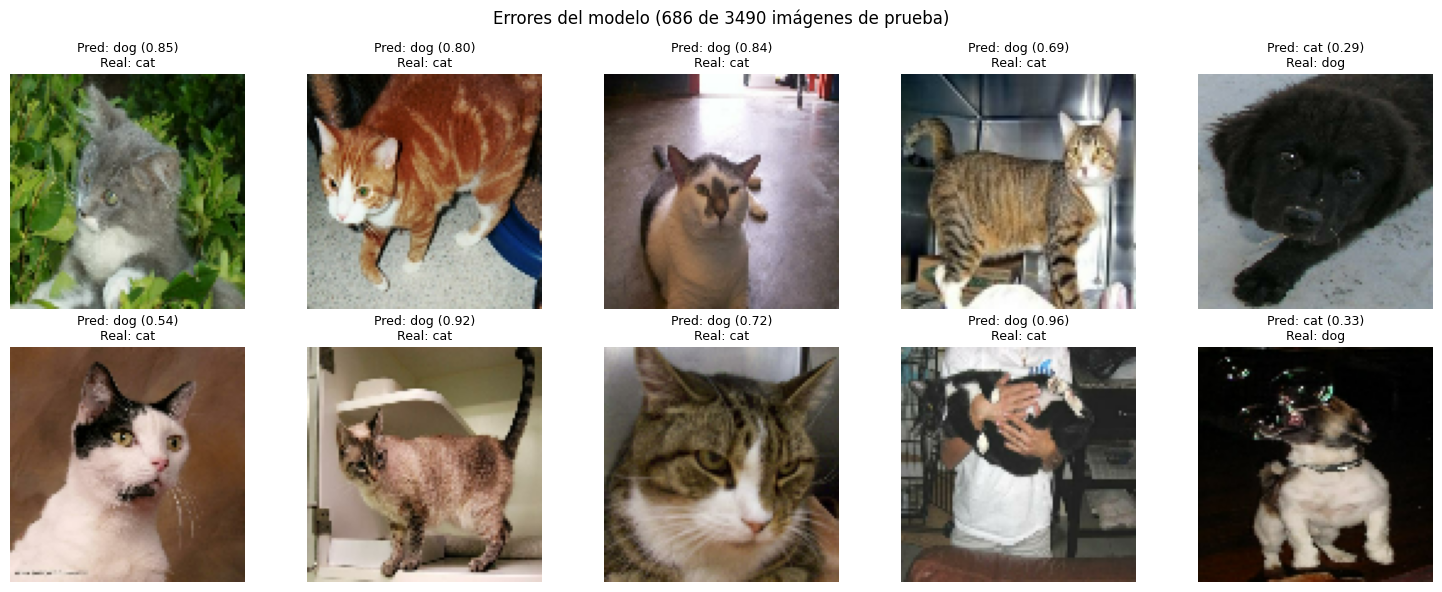

In [20]:
mostrar_errores(x_test, modelo_3, y_test, n_samples=10)

# 7. Modelo 4: transfer learning con MobileNetV2

MobileNetV2 preentrenada en ImageNet, congelada, con una capa densa de salida.

In [21]:
pre_modelo = tf.keras.applications.MobileNetV2(input_shape=image_size,
                                                     include_top=False)
pre_modelo.trainable = False  # Congelar las capas del modelo preentrenado

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [22]:
# Preprocesamiento de entrada para el modelo MobileNetV2
pre_input = tf.keras.applications.mobilenet_v2.preprocess_input

In [23]:
inputs = tf.keras.Input(shape=image_size, name='input')

# Preprocesar la entrada con la función del modelo preentrenado
x = pre_input(inputs)

# Pasar las imágenes preprocesadas por el modelo MobileNetV2
x = pre_modelo(x)

# Añadir una capa de "flatten" para convertir la salida 2D en 1D
flat = tf.keras.layers.Flatten()(x)

# Añadir una capa densa para clasificación
outputs = tf.keras.layers.Dense(1, activation='sigmoid')(flat)

# Crear el modelo
modelo_tl = tf.keras.Model(inputs, outputs)

# Mostrar el resumen del modelo
modelo_tl.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 11520)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        11,521 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,505 (8.66 MB)

 Trainable params: 11,521 (45.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [24]:
modelo_tl.compile(
    optimizer='adam',
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

epochs = 2

es_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True,
    verbose=1)

historia = modelo_tl.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[es_callback],
)

Epoch 1/2
546/546 ━━━━━━━━━━━━━━━━━━━━ 26s 29ms/step - accuracy: 0.9541 - loss: 0.1486 - val_accuracy: 0.9609 - val_loss: 0.1338
Epoch 2/2
546/546 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9753 - loss: 0.0718 - val_accuracy: 0.9604 - val_loss: 0.1611
Restoring model weights from the end of the best epoch: 1.


In [25]:
resultados = modelo_tl.evaluate(test_ds, verbose=1)
print('Test Loss: {}'.format(resultados[0]))
print('Test Accuracy: {}'.format(resultados[1]))

110/110 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.9607 - loss: 0.1480
Test Loss: 0.147994264960289
Test Accuracy: 0.9607449769973755


**Análisis:** exactitud de 0,96 en prueba con solo dos épocas. MobileNetV2 ya trae, de su entrenamiento en ImageNet, filtros que reconocen bordes, texturas y partes de animales; solo hace falta entrenar la capa de salida. Es el mejor modelo con diferencia.

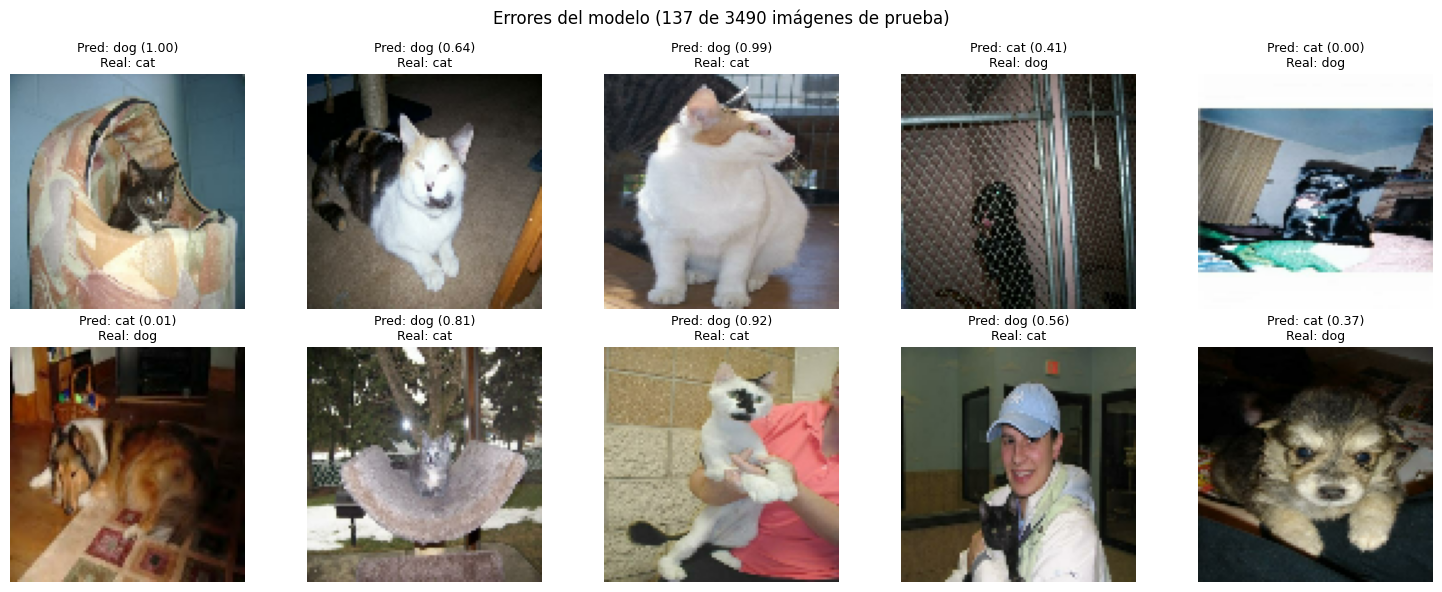

In [26]:
mostrar_errores(x_test, modelo_tl, y_test, n_samples=10)

# 8. Generalización con imágenes nuevas

Tres fotos de Wikimedia Commons que no están en el dataset.

In [27]:
def leer_imagen(image_path, target_size=None):
    image = tf.keras.preprocessing.image.load_img(image_path,
                target_size=target_size)
    image = tf.keras.preprocessing.image.img_to_array(image)
    image = image.astype(np.uint8)
    return image

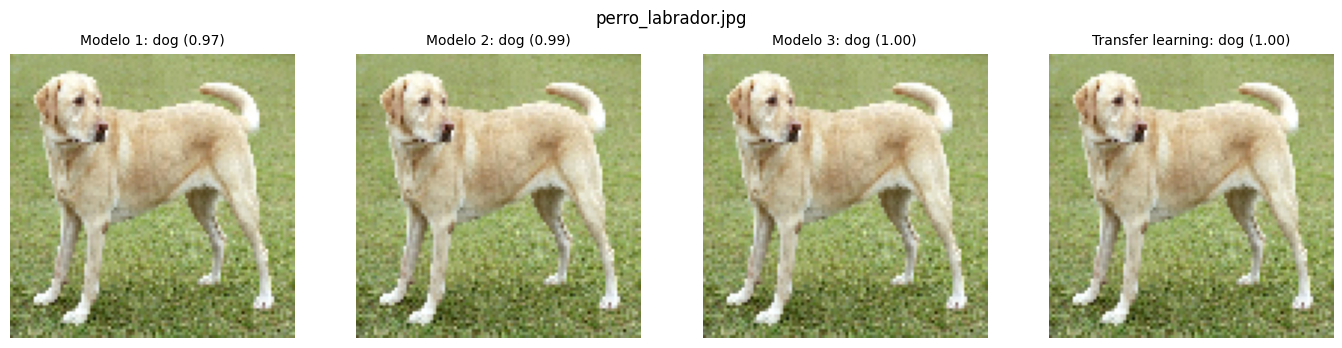

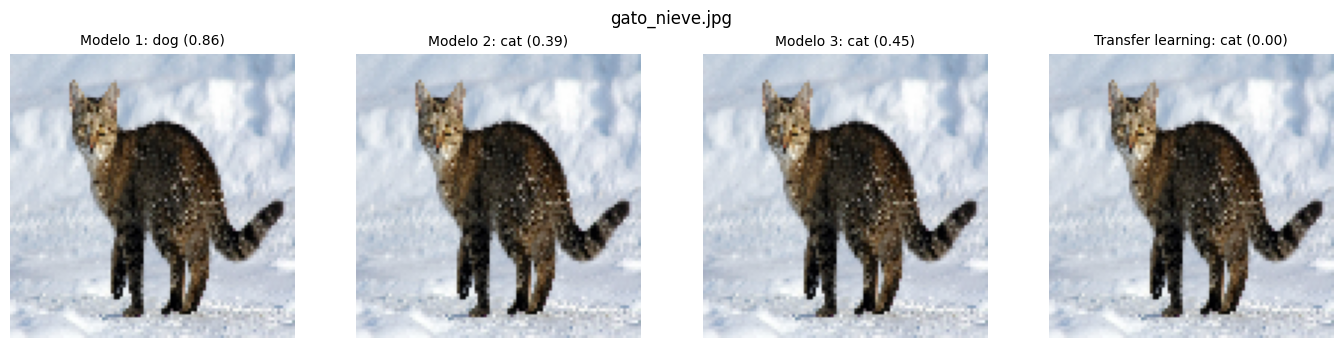

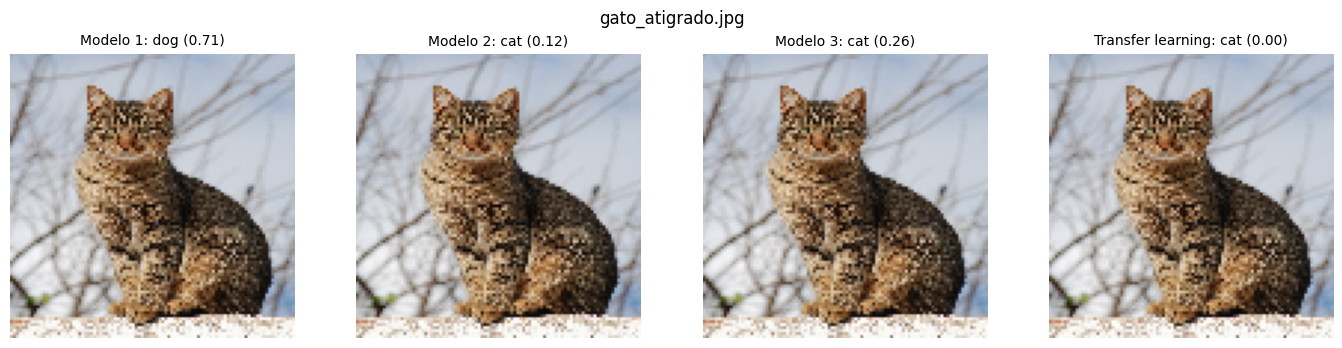

In [29]:
import requests, os

# Fotos de Wikimedia Commons (licencias libres)
imagenes = {
    'perro_labrador.jpg': 'https://upload.wikimedia.org/wikipedia/commons/2/26/YellowLabradorLooking_new.jpg',
    'gato_nieve.jpg': 'https://upload.wikimedia.org/wikipedia/commons/b/b6/Felis_catus-cat_on_snow.jpg',
    'gato_atigrado.jpg': 'https://upload.wikimedia.org/wikipedia/commons/4/4d/Cat_November_2010-1a.jpg',
}
cabecera = {'User-Agent': 'coursework-notebook/1.0 (https://github.com/Santy012/coursework)'}
modelos = {'Modelo 1': modelo_1, 'Modelo 2': modelo_2, 'Modelo 3': modelo_3, 'Transfer learning': modelo_tl}

for nombre, url in imagenes.items():
    if not os.path.exists(nombre):
        r = requests.get(url, headers=cabecera, timeout=30)
        r.raise_for_status()
        open(nombre, 'wb').write(r.content)
    imagen = leer_imagen(nombre, image_size[:2])
    plt.figure(figsize=(14, 3.5))
    for k, (titulo, modelo) in enumerate(modelos.items()):
        prob = float(modelo(np.expand_dims(imagen, 0), training=False)[0][0])
        plt.subplot(1, 4, k + 1)
        plt.imshow(imagen)
        plt.title(f'{titulo}: {class_names[int(prob >= 0.5)]} ({prob:.2f})', fontsize=10)
        plt.axis('off')
    plt.suptitle(nombre)
    plt.tight_layout()
    plt.show()

**Análisis:** las fotos nuevas confirman lo que mostró la prueba (la probabilidad es la de "perro"):

- El modelo 1 acierta el perro pero confunde a los dos gatos con perros (0,86 y 0,71).
- Los modelos 2 y 3 aciertan las tres imágenes, aunque con el gato en la nieve quedan cerca del umbral (0,39 y 0,45).
- El transfer learning acierta las tres con total seguridad: 1,00 para el perro y 0,00 para los dos gatos.